# Glucose-Level Food Recommender: Training and Evaluation (ECLAT)
Trains the ECLAT model and evaluates it on unseen people.

## Part 1: Setup
### Step 1: Install, import and settings

In [1]:
%pip install -q pyECLAT

In [2]:
import os, sys, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact, spearmanr

from pyECLAT import ECLAT
from mlxtend.frequent_patterns import apriori, fpgrowth
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

In [ ]:
# SETTINGS
DATA_DIR = os.environ.get("DATA_DIR", "/content/drive/MyDrive/NHANES")
TRANSACTIONS_FILE = os.path.join(DATA_DIR, "glucose_food_training_data_v3.csv")
NUTRITION_FILE    = os.path.join(DATA_DIR, "food_group_nutrition.csv")
ITEMS_FILE        = os.path.join(DATA_DIR, "food_group_items.csv")
ITEM_BASKETS_FILE = os.path.join(DATA_DIR, "food_group_item_baskets.csv")

SEED = 42
MIN_SUPPORT = 0.08
MIN_PEOPLE = 10
MIN_POOL = 80
TOP_K = 10
N_PAIRS = 5

# Glucose levels
LEVEL_START, LEVEL_STEP, LEVEL_TOP = 80, 20, 200
LEVEL_EDGES = [0] + list(range(LEVEL_START, LEVEL_TOP + 1, LEVEL_STEP)) + [np.inf]
LEVELS = ([f"<{LEVEL_START}"] + [f"{a}-{a + LEVEL_STEP - 1}" for a in range(LEVEL_START, LEVEL_TOP, LEVEL_STEP)]
          + [f"{LEVEL_TOP}+"])

# Nutrition limits per level
def level_limits(i):
    if i <= 1:
        return dict(sugar=15, net_carb=60, sat_fat=10, carb_penalty=0.0)
    k = i - 1
    return dict(sugar=13 - k, net_carb=52 - 7 * k, sat_fat=10 if k <= 2 else 8, carb_penalty=round(0.15 * k, 2))
LIMITS = {lv: level_limits(i) for i, lv in enumerate(LEVELS)}

FIBER_EXCEPTION = dict(min_fiber=1.5, max_sugar=12)       # whole, fibre-rich foods (e.g. fruit) may exceed the sugar limit
NEVER = {953, 924, 925, 929, 923,                          # sports/energy drinks, soft drinks, fruit drinks, sweet tea
         581, 241, 275, 263, 714, 712, 544, 754, 521}      # pizza, nuggets, burgers, fried shrimp, fries, chips, snacks, onion rings, biscuits
NEVER_PREFIX = {93, 81, 82, 83}                            # alcohol (930-939); butter, oils, dressings (810-839)
FROM_100 = {612, 641, 115, 252}                            # from 100 mg/dL: fruit juices, chocolate milk, deli/processed meats

# Clinical label shown next to the level
def clinical_band(g):
    return "Low (hypoglycemia)" if g < 70 else "Normal" if g < 100 else "Prediabetes" if g < 126 else "Diabetes"

# "people like you"
AGE_CUTS, AGE_GROUPS = [17, 39, 59, 200], ["18-39", "40-59", "60+"]

print(pd.DataFrame(LIMITS).T.rename_axis("glucose level (mg/dL)"))

                       sugar  net_carb  sat_fat  carb_penalty
glucose level (mg/dL)                                        
<80                     15.0      60.0     10.0          0.00
80-99                   15.0      60.0     10.0          0.00
100-119                 12.0      45.0     10.0          0.15
120-139                 11.0      38.0     10.0          0.30
140-159                 10.0      31.0      8.0          0.45
160-179                  9.0      24.0      8.0          0.60
180-199                  8.0      17.0      8.0          0.75
200+                     7.0      10.0      8.0          0.90


### Step 2: Load the transactions and the nutrition table

In [4]:
if "google.colab" in sys.modules and not os.environ.get("DATA_DIR"):
    from google.colab import drive
    drive.mount("/content/drive")

data = pd.read_csv(TRANSACTIONS_FILE)
NUT = pd.read_csv(NUTRITION_FILE).set_index("code")
food_cols = [c for c in data.columns if c not in ["SEQN", "Glucose_mg_dL", "Age", "Gender"]]

def level_of(glucose):
    return pd.cut(pd.Series(glucose, dtype=float), LEVEL_EDGES, labels=LEVELS, right=False).astype(str)

def age_group_of(age):
    return pd.cut(pd.Series(age, dtype=float), AGE_CUTS, labels=AGE_GROUPS).astype(str)

# Pipeline step 1
class AddLevelAndGroup(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        X["Level"] = level_of(X.Glucose_mg_dL).values
        X["Group"] = (age_group_of(X.Age) + " " + X.Gender.str.lower()).values
        return X

data = AddLevelAndGroup().fit_transform(data)
GROUPS = sorted(data.Group.unique())

def pretty(col): return col.rsplit("_", 1)[0].replace("_", " ")
def code_of(col): return int(col.rsplit("_", 1)[1])

print("Transactions:", len(data), "| items (food groups):", len(food_cols), "| nutrition rows:", len(NUT))

print('\nPeople per glucose level:'); print(data.Level.value_counts().reindex(LEVELS, fill_value=0).to_string())

Transactions: 1885 | items (food groups): 184 | nutrition rows: 184

People per glucose level:
Level
<80         17
80-99      780
100-119    928
120-139    118
140-159     23
160-179      4
180-199      4
200+        11


### Step 2b: Overview of the prepared dataset

In [5]:
prepared = pd.read_csv(TRANSACTIONS_FILE)
meta = ["SEQN", "Glucose_mg_dL", "Age", "Gender"]
print("Transactions CSV shape:", prepared.shape,
      f"-> {prepared.shape[0]} people, {len(meta)} person columns + {prepared.shape[1] - len(meta)} food-group columns")
print("Nutrition table shape: ", NUT.shape, f"-> {NUT.shape[0]} food groups")

Transactions CSV shape: (1885, 188) -> 1885 people, 4 person columns + 184 food-group columns
Nutrition table shape:  (184, 8) -> 184 food groups


In [6]:
prepared.iloc[:, :10].head()

,SEQN,Glucose_mg_dL,Age,Gender,Milk_111,Evaporated_or_condensed_milk_112,Almond_or_soy_milk_113,Yogurt_114,Chocolate_milk_115,Cocoa_or_milk_powder_mix_118
0,93708,122.0,66,Female,1,0,0,0,0,0
1,93711,107.0,56,Male,1,0,0,1,1,0
2,93717,91.0,22,Male,0,0,0,0,0,0
3,93721,104.0,60,Female,1,0,0,0,0,0
4,93722,101.0,60,Female,1,0,0,0,1,0


In [7]:
prepared[meta].info()
print("\nFood-group columns by type:", prepared[food_cols].dtypes.astype(str).value_counts().to_dict())
print("Food-group columns contain only 0/1:", bool(prepared[food_cols].isin([0, 1]).all().all()))

<class 'pandas.DataFrame'>
RangeIndex: 1885 entries, 0 to 1884
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SEQN           1885 non-null   int64  
 1   Glucose_mg_dL  1885 non-null   float64
 2   Age            1885 non-null   int64  
 3   Gender         1885 non-null   str    
dtypes: float64(1), int64(2), str(1)
memory usage: 59.0 KB

Food-group columns by type: {'int64': 184}
Food-group columns contain only 0/1: True


In [8]:
print(prepared.Gender.value_counts().to_string(), "\n")
summary = prepared[["Glucose_mg_dL", "Age"]].assign(basket_size=prepared[food_cols].sum(axis=1))
summary.describe().round(1)

Gender
Female    983
Male      902 



,Glucose_mg_dL,Age,basket_size
count,1885.0,1885.0,1885.0
mean,104.0,47.3,14.5
std,19.6,18.1,5.3
min,47.0,18.0,1.0
25%,95.0,32.0,11.0
50%,101.0,47.0,14.0
75%,109.0,61.0,18.0
max,451.0,80.0,34.0


In [9]:
print("Missing values in the transactions CSV:", int(prepared.isna().sum().sum()))
print("Missing values in the nutrition table: ", int(NUT.isna().sum().sum()))

Missing values in the transactions CSV: 0
Missing values in the nutrition table:  0


In [10]:
print("Duplicate rows:                    ", int(prepared.duplicated().sum()))
print("Duplicate person IDs (SEQN):       ", int(prepared.SEQN.duplicated().sum()))
print("Duplicate food codes in nutrition: ", int(NUT.index.duplicated().sum()))

Duplicate rows:                     0
Duplicate person IDs (SEQN):        0
Duplicate food codes in nutrition:  0


## Part 2: Model building blocks
### Step 3: ECLAT, pooling, nutrition filter and scoring functions

In [11]:
# ECLAT helpers
def to_eclat_format(onehot_rows):
    return pd.DataFrame([list(onehot_rows.columns[row.astype(bool)]) for row in onehot_rows.values])

def min_support_for(n): return max(MIN_SUPPORT, MIN_PEOPLE / n)

def wilson_ci(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return centre - half, centre + half

def bh(p):
    p = np.asarray(p, float); n = len(p)
    if n == 0: return p
    order = np.argsort(p); q = p[order] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(q, 1); return out

def mine_group(rows, everyone, max_combination=2):
    n = len(rows)
    eclat = ECLAT(data=to_eclat_format(rows), verbose=False)
    _, supports = eclat.fit(min_support=min_support_for(n), min_combination=1,
                            max_combination=max_combination, separator=" & ", verbose=False)
    others = everyone.drop(index=rows.index, errors="ignore")
    single = rows.mean()
    recs = []
    for key, sup in supports.items():
        items = tuple(key.split(" & ")); k = int(round(sup * n))
        if len(items) == 1:
            f = items[0]; k_out = int(others[f].sum()); n_out = len(others)
            lift = sup / ((k + k_out) / (n + n_out))
            p = fisher_exact([[k, n - k], [k_out, n_out - k_out]])[1]
        else:
            a, b = items; ka, kb = int(rows[a].sum()), int(rows[b].sum())
            lift = sup / (single[a] * single[b])
            p = fisher_exact([[k, ka - k], [kb - k, n - ka - kb + k]])[1]
        lo, hi = wilson_ci(k, n)
        recs.append(dict(items=items, size=len(items), count=k, support=sup, ci_low=lo, ci_high=hi, lift=lift, p=p))
    t = pd.DataFrame(recs, columns=["items", "size", "count", "support", "ci_low", "ci_high", "lift", "p"])
    t["q"] = bh(t.p.values)
    return t

def make_pools(frame, min_people=MIN_POOL):
    counts = frame.Level.value_counts().reindex(LEVELS, fill_value=0)
    mid = int(np.argmax(counts.values))
    pool_of = {LEVELS[mid]: (LEVELS[mid],)}
    for side in (LEVELS[:mid], LEVELS[mid + 1:][::-1]):
        current, last = [], None
        for lv in side:
            current.append(lv)
            if counts[current].sum() >= min_people:
                pool = tuple(sorted(current, key=LEVELS.index))
                for l in current: pool_of[l] = pool
                current, last = [], pool
        if current:
            target = last if last else pool_of[LEVELS[mid]]
            pool = tuple(sorted(set(target) | set(current), key=LEVELS.index))
            for l in pool: pool_of[l] = pool
    return pool_of

def pool_name(pool):
    lo, hi = LEVEL_EDGES[LEVELS.index(pool[0])], LEVEL_EDGES[LEVELS.index(pool[-1]) + 1]
    if lo == 0 and np.isinf(hi): return "all levels"
    if lo == 0: return f"below {int(hi)}"
    if np.isinf(hi): return f"{int(lo)} and above"
    return f"{int(lo)}-{int(hi) - 1}"

# Nutrition filter
def is_fit(col, level):
    c = code_of(col)
    if c not in NUT.index or c in NEVER or c // 10 in NEVER_PREFIX: return False
    if LEVELS.index(level) >= LEVELS.index("100-119") and c in FROM_100: return False
    n, lim = NUT.loc[c], LIMITS[level]
    sugar_ok = n.sugar_100g <= lim["sugar"] or (n.fiber_100g >= FIBER_EXCEPTION["min_fiber"] and n.sugar_100g <= FIBER_EXCEPTION["max_sugar"])
    return bool(sugar_ok and n.net_carb_100g <= lim["net_carb"] and n.sat_fat_100g <= lim["sat_fat"])

FIT = {lv: {c for c in food_cols if is_fit(c, lv)} for lv in LEVELS}

# The model
def train_model(frame, pairs=True):
    pool_of = make_pools(frame)
    pool_tables = {pool: mine_group(frame.loc[frame.Level.isin(pool), food_cols], frame[food_cols], 2 if pairs else 1)
                   for pool in sorted(set(pool_of.values()), key=lambda p: LEVELS.index(p[0]))}
    group_tables = {g: mine_group(frame.loc[frame.Group == g, food_cols], frame[food_cols], 1) for g in GROUPS}
    sizes = {"pool": {p: int(frame.Level.isin(p).sum()) for p in pool_tables}, "group": frame.Group.value_counts().to_dict()}
    return dict(pool_of=pool_of, pool_tables=pool_tables, group_tables=group_tables, sizes=sizes)

def singles(t):
    s = t[t["size"] == 1]
    return {it[0]: r for it, r in zip(s["items"], s.to_dict("records"))}

def recommend_foods(model, level, group, k=TOP_K):
    pt = singles(model["pool_tables"][model["pool_of"][level]]); gt = singles(model["group_tables"][group])
    w = LIMITS[level]["carb_penalty"]; rows = []
    for f in (set(pt) | set(gt)) & FIT[level]:
        ls, gs = pt.get(f, {}).get("support", 0.0), gt.get(f, {}).get("support", 0.0)
        support = (ls + gs) / 2
        nc = NUT.loc[code_of(f), "net_carb_100g"]
        rows.append(dict(food=f, score=support * (1 - w * min(nc / 40, 1)), support=support,
                         level_support=ls, group_support=gs,
                         level_lift=pt.get(f, {}).get("lift", np.nan), level_q=pt.get(f, {}).get("q", np.nan),
                         net_carb_100g=nc))
    return pd.DataFrame(rows).sort_values(["score", "support"], ascending=False).head(k).reset_index(drop=True)

def recommend_pairs(model, level, k=N_PAIRS):
    t = model["pool_tables"][model["pool_of"][level]]
    t = t[(t["size"] == 2) & (t.lift > 1) & (t.q < 0.05)]
    t = t[t["items"].apply(lambda it: all(i in FIT[level] for i in it))]
    return t.sort_values("support", ascending=False).head(k).reset_index(drop=True)

print("Mining pools (all data): each glucose level -> the transactions ECLAT mines for it")
pools_all = make_pools(data)
for lv in LEVELS:
    print(f"  {lv:>8s} -> {pool_name(pools_all[lv]):>15s}  ({int(data.Level.isin(pools_all[lv]).sum())} transactions)")

Mining pools (all data): each glucose level -> the transactions ECLAT mines for it
       <80 ->       below 100  (797 transactions)
     80-99 ->       below 100  (797 transactions)
   100-119 ->         100-119  (928 transactions)
   120-139 ->   120 and above  (160 transactions)
   140-159 ->   120 and above  (160 transactions)
   160-179 ->   120 and above  (160 transactions)
   180-199 ->   120 and above  (160 transactions)
      200+ ->   120 and above  (160 transactions)


In [12]:
def show_foods(r):
    return pd.DataFrame({"food": r.food.map(pretty), "score": r.score.round(3),
                         "support % (avg)": (r.support * 100).round(1),
                         "% at your level": (r.level_support * 100).round(1),
                         "% your age+gender": (r.group_support * 100).round(1),
                         "lift (level)": r.level_lift.round(2), "q": r.level_q.round(3),
                         "net carb g/100g": r.net_carb_100g.round(1)}).to_string(index=False)

def show_pairs(t):
    if len(t) == 0: return "none for this level"
    return pd.DataFrame({"pair": [" + ".join(pretty(i) for i in it) for it in t["items"]],
                         "support %": (t.support * 100).round(1),
                         "95% CI": [f"{a*100:.0f}-{b*100:.0f}%" for a, b in zip(t.ci_low, t.ci_high)],
                         "lift": t.lift.round(2), "q": t.q.round(3)}).to_string(index=False)

def recommend(model, glucose_mg_dl, age, gender, k=TOP_K):
    gender = str(gender).strip().capitalize()
    if gender not in ("Male", "Female"): raise ValueError("gender must be 'male' or 'female'")
    if age < 18: raise ValueError("the model was built on adults (18+)")
    if not 20 <= glucose_mg_dl <= 600: raise ValueError("glucose must be between 20 and 600 mg/dL")
    level = level_of(glucose_mg_dl)[0]; group = f"{age_group_of(age)[0]} {gender.lower()}"
    pool = model["pool_of"][level]
    print(f"Fasting glucose {glucose_mg_dl} mg/dL -> level {level} mg/dL ({clinical_band(glucose_mg_dl)})")
    print(f"People like you: {group} ({model['sizes']['group'][group]} transactions) | "
          f"same glucose level: {pool_name(pool)} mg/dL ({model['sizes']['pool'][pool]} transactions)")
    print(f"Nutrition limits for this level (per 100 g): sugar <= {LIMITS[level]['sugar']} g, "
          f"net carb <= {LIMITS[level]['net_carb']} g, sat. fat <= {LIMITS[level]['sat_fat']} g, carb penalty {LIMITS[level]['carb_penalty']}")
    print("\nRecommended foods:"); print(show_foods(recommend_foods(model, level, group, k)))
    print("\nGood combinations (fit pairs eaten together significantly more than chance):")
    print(show_pairs(recommend_pairs(model, level)))
    if glucose_mg_dl < 70:
        print("\nNote: below 70 mg/dL is low blood glucose. Seek medical advice.")
    elif glucose_mg_dl >= 100:
        print("\nNote: a fasting glucose in this range should be confirmed and discussed with a doctor.")

print("Fit food groups per level:")
print(pd.Series({lv: len(FIT[lv]) for lv in LEVELS}).to_string())
print("\nRemoved at each step (foods fit at the previous level but not at this one):")
for a, b in zip(LEVELS, LEVELS[1:]):
    removed = sorted(FIT[a] - FIT[b], key=pretty)
    print(f"  {a:>8s} -> {b:<8s}: {', '.join(pretty(c) for c in removed) if removed else '(same limits)'}")

Fit food groups per level:
<80        122
80-99      122
100-119    108
120-139     99
140-159     90
160-179     88
180-199     77
200+        62

Removed at each step (foods fit at the previous level but not at this one):
       <80 -> 80-99   : (same limits)
     80-99 -> 100-119 : Bread unspecified, Chocolate milk, Citrus juice, Crackers unspecified, Deli meats and sausages, Fruit juice, Fruit nectar, Fruit salad and cocktail, Grain based meat substitute, Oat bread, Peanut butter sandwich, Plantain and cassava, Plantain fritters, White bread and rolls
   100-119 -> 120-139 : Chinese pancake, Gelatin dessert, Gluten free bread, Multigrain bread, Raw oats and bran, Rye bread, Tortillas and cornbread, Waffles, Wheat bread
   120-139 -> 140-159 : Cream, Duck, French toast, Horchata and grain drinks, Lamb, Pancakes, Peanut butter, Sour cream and dips, Yogurt
   140-159 -> 160-179 : Pasta and noodles, Rice cakes and dosa
   160-179 -> 180-199 : Baked or boiled potato, Cheese dip and gril

### Step 3b: The scikit-learn Pipeline

In [13]:
# Pipeline step 2
class ECLATRecommender(BaseEstimator):
    def __init__(self, pairs=True, top_k=TOP_K):
        self.pairs = pairs
        self.top_k = top_k

    def fit(self, X, y=None):
        self.model_ = train_model(X, pairs=self.pairs)
        return self

    def predict(self, X):
        top = {}
        for (lv, g), people in X.groupby(["Level", "Group"]):
            foods = list(recommend_foods(self.model_, lv, g, self.top_k).food)
            for i in people.index:
                top[i] = foods
        return pd.Series(top).reindex(X.index)

    def _hits(self, X):
        top = self.predict(X)
        return pd.Series([X.loc[i, top[i]].sum() for i in X.index], index=X.index)

    def hit_rate(self, X, y=None):
        return float((self._hits(X) > 0).mean())

    def precision(self, X, y=None):
        return float((self._hits(X) / self.top_k).mean())

    def score(self, X, y=None):
        return self.hit_rate(X)

# The Pipeline
def make_sucrose_pipeline(pairs=True):
    return Pipeline([("levels_groups", AddLevelAndGroup()),
                     ("eclat", ECLATRecommender(pairs=pairs))])

print(make_sucrose_pipeline())

Pipeline(steps=[('levels_groups', AddLevelAndGroup()),
                ('eclat', ECLATRecommender())])


## Part 3: Train with ECLAT
### Step 4: Train / test split

In [14]:
train, test = train_test_split(data, test_size=0.20, stratify=data.Group, random_state=SEED)
print(pd.DataFrame({"train": train.Level.value_counts(), "test": test.Level.value_counts()}).reindex(LEVELS).fillna(0).astype(int))

         train  test
Level               
<80         13     4
80-99      626   154
100-119    753   175
120-139     88    30
140-159     16     7
160-179      3     1
180-199      2     2
200+         7     4


### Step 5: Mine with pyECLAT

In [15]:
t0 = time.time()
pipe_train = make_sucrose_pipeline().fit(train)
model_train = pipe_train.named_steps["eclat"].model_
print(f"ECLAT finished in {time.time() - t0:.0f} s\n")
for p, t in model_train["pool_tables"].items():
    print(f"level pool {pool_name(p):>15s}: {model_train['sizes']['pool'][p]:4d} transactions, "
          f"{(t['size'] == 1).sum():3d} frequent foods, {(t['size'] == 2).sum():4d} frequent pairs")
for g, t in model_train["group_tables"].items():
    print(f"group {g:>20s}: {model_train['sizes']['group'][g]:4d} transactions, {len(t):3d} frequent foods")

ECLAT finished in 50 s

level pool       below 100:  639 transactions,  58 frequent foods,  208 frequent pairs
level pool         100-119:  753 transactions,  54 frequent foods,  247 frequent pairs
level pool   120 and above:  116 transactions,  50 frequent foods,  246 frequent pairs
group         18-39 female:  304 transactions,  56 frequent foods
group           18-39 male:  275 transactions,  49 frequent foods
group         40-59 female:  248 transactions,  55 frequent foods
group           40-59 male:  234 transactions,  54 frequent foods
group           60+ female:  235 transactions,  55 frequent foods
group             60+ male:  212 transactions,  58 frequent foods


In [16]:
p = model_train["pool_of"]["100-119"]
t = model_train["pool_tables"][p]
print(f"=== level pool {pool_name(p)}: most frequent pairs with significant lift ===")
print(show_pairs(t[(t['size'] == 2) & (t.lift > 1) & (t.q < 0.05)].sort_values("support", ascending=False).head(8)))

=== level pool 100-119: most frequent pairs with significant lift ===
                                            pair  support % 95% CI  lift     q
  White bread and rolls + Pizza and pasta dishes       32.4 29-36%  1.08 0.032
Mayonnaise and dressings + White bread and rolls       22.4 20-26%  1.22 0.000
                              Milk + Fresh fruit       21.5 19-25%  1.13 0.039
            Burgers and sandwiches + Soft drinks       21.0 18-24%  1.28 0.000
 White bread and rolls + Deli meats and sausages       20.7 18-24%  1.33 0.000
                  Salad vegetables + Fresh fruit       20.5 18-23%  1.21 0.001
     Mayonnaise and dressings + Salad vegetables       20.2 17-23%  1.50 0.000
                 Cooked vegetables + Fresh fruit       19.0 16-22%  1.19 0.003


## Part 4: Verify ECLAT
### Step 6: Same itemsets and supports as Apriori and FP-Growth

In [17]:
rows = []
sets = [(f"level {pool_name(p)}", train.loc[train.Level.isin(p), food_cols], t, 2) for p, t in model_train["pool_tables"].items()] + \
       [(f"group {g}", train.loc[train.Group == g, food_cols], t, 1) for g, t in model_train["group_tables"].items()]
for name, rows_, t, ml in sets:
    oh = rows_.astype(bool); ms = min_support_for(len(oh))
    ec = {frozenset(i): s for i, s in zip(t["items"], t.support)}
    def same(res):
        d = {frozenset(s): v for s, v in zip(res.itemsets, res.support)}
        return d.keys() == ec.keys() and all(np.isclose(v, ec[k]) for k, v in d.items())
    rows.append({"transactions": name, "itemsets (ECLAT)": len(ec),
                 "same as Apriori": same(apriori(oh, min_support=ms, use_colnames=True, max_len=ml)),
                 "same as FP-Growth": same(fpgrowth(oh, min_support=ms, use_colnames=True, max_len=ml))})
print(pd.DataFrame(rows).to_string(index=False))

       transactions  itemsets (ECLAT)  same as Apriori  same as FP-Growth
    level below 100               266             True               True
      level 100-119               301             True               True
level 120 and above               296             True               True
 group 18-39 female                56             True               True
   group 18-39 male                49             True               True
 group 40-59 female                55             True               True
   group 40-59 male                54             True               True
   group 60+ female                55             True               True
     group 60+ male                58             True               True


## Part 5: Evaluate support and lift on unseen people
### Step 7: Do the supports and lifts hold on the test set?

In [18]:
def test_support(rows_, items): return rows_[list(items)].all(axis=1).mean()
def test_lift(rows_, everyone, items):
    if len(items) == 1:
        s_all = everyone[items[0]].mean(); return rows_[items[0]].mean() / s_all if s_all else np.nan
    a, b = items; sa, sb = rows_[a].mean(), rows_[b].mean()
    return test_support(rows_, items) / (sa * sb) if sa * sb else np.nan

ev = []
for kind, tables, select in [("level pool", model_train["pool_tables"], lambda key: test.Level.isin(key)),
                             ("age+gender", model_train["group_tables"], lambda key: test.Group == key)]:
    for key, t in tables.items():
        te = test.loc[select(key), food_cols]
        for _, r in t.iterrows():
            ev.append({"kind": kind, "size": r["size"], "train_support": r.support, "train_lift": r.lift, "q": r.q,
                       "test_support": test_support(te, r["items"]), "test_lift": test_lift(te, test[food_cols], r["items"])})
ev = pd.DataFrame(ev)
out = []
for (kind, size), e in ev.groupby(["kind", "size"]):
    strong = e[e.train_lift >= 1.2]; sig = strong[strong.q < 0.05]
    out.append({"itemsets": f"{kind}, {'single foods' if size == 1 else 'pairs'}", "n": len(e),
                "support rank corr.": spearmanr(e.train_support, e.test_support)[0],
                "mean |support gap|": (e.train_support - e.test_support).abs().mean(),
                "train lift>=1.2": len(strong), "% still lift>1": 100 * (strong.test_lift > 1).mean() if len(strong) else np.nan,
                "of those q<0.05": len(sig), "% (q<0.05) still lift>1": 100 * (sig.test_lift > 1).mean() if len(sig) else np.nan})
print(pd.DataFrame(out).round(3).to_string(index=False))

                itemsets   n  support rank corr.  mean |support gap|  train lift>=1.2  % still lift>1  of those q<0.05  % (q<0.05) still lift>1
age+gender, single foods 327               0.890               0.041               73          73.973               20                   85.000
level pool, single foods 162               0.903               0.035                9          33.333                0                      NaN
       level pool, pairs 701               0.684               0.028              208          75.962               88                   88.636


## Part 6: Evaluate the recommendations
### Step 8: Hit Rate@10, precision@10 and recall@10

In [19]:
from math import comb

def evaluate(f_train, f_eval):
    m = make_sucrose_pipeline(pairs=False).fit(f_train).named_steps["eclat"].model_
    overall = f_train[food_cols].mean()
    res = {k: {"hit@10": [], "precision@10": [], "recall@10": []} for k in ["ECLAT blend (ours)", "ECLAT level only", "ECLAT age+gender only", "global list", "random fit foods"]}
    for (lv, g), people in f_eval.groupby(["Level", "Group"]):
        fit = sorted(FIT[lv]); w = LIMITS[lv]["carb_penalty"]
        pt = {f: r["support"] for f, r in singles(m["pool_tables"][m["pool_of"][lv]]).items()}
        gt = {f: r["support"] for f, r in singles(m["group_tables"][g]).items()}
        pen = lambda s: {f: v * (1 - w * min(NUT.loc[code_of(f), "net_carb_100g"] / 40, 1)) for f, v in s.items() if f in FIT[lv]}
        top = lambda s: [f for f, _ in sorted(pen(s).items(), key=lambda x: -x[1])[:TOP_K]]
        lists = {"ECLAT blend (ours)": top({f: (pt.get(f, 0) + gt.get(f, 0)) / 2 for f in set(pt) | set(gt)}),
                 "ECLAT level only": top(pt), "ECLAT age+gender only": top(gt),
                 "global list": top(overall.to_dict())}
        eaten_fit = people[fit].sum(axis=1)
        for name, L in lists.items():
            hits = people[L].sum(axis=1)
            res[name]["hit@10"] += list((hits > 0).astype(float))
            res[name]["precision@10"] += list(hits / TOP_K)
            res[name]["recall@10"] += list((hits / eaten_fit.replace(0, np.nan)).fillna(0))
        res["random fit foods"]["precision@10"] += list(people[fit].mean(axis=1))
        res["random fit foods"]["recall@10"] += list((TOP_K / len(fit)) * (eaten_fit > 0))
        res["random fit foods"]["hit@10"] += [1 - comb(len(fit) - k, TOP_K) / comb(len(fit), TOP_K) for k in eaten_fit.astype(int)]
    return pd.DataFrame({k: {kk: np.mean(vv) for kk, vv in v.items()} for k, v in res.items()}).T

t0 = time.time()
folds = [evaluate(train.iloc[a], train.iloc[v]) for a, v in StratifiedKFold(5, shuffle=True, random_state=SEED).split(train, train.Group)]
print(f"5-fold cross-validation finished in {time.time() - t0:.0f} s\n")
print("Cross-validation mean:"); print((sum(folds) / len(folds)).round(3).to_string())
print("\nFold-to-fold std:"); print(pd.concat(folds).groupby(level=0).std().round(3).to_string())

5-fold cross-validation finished in 125 s

Cross-validation mean:
                       hit@10  precision@10  recall@10
ECLAT blend (ours)      0.914         0.292      0.438
ECLAT level only        0.912         0.289      0.434
ECLAT age+gender only   0.912         0.290      0.435
global list             0.914         0.292      0.436
random fit foods        0.441         0.059      0.087

Fold-to-fold std:
                       hit@10  precision@10  recall@10
ECLAT age+gender only   0.020         0.014      0.015
ECLAT blend (ours)      0.020         0.015      0.014
ECLAT level only        0.019         0.014      0.012
global list             0.019         0.016      0.016
random fit foods        0.013         0.002      0.002


Test set (used once):
                       hit@10  precision@10  recall@10
ECLAT blend (ours)      0.905         0.292      0.440
ECLAT level only        0.905         0.291      0.436
ECLAT age+gender only   0.905         0.291      0.437
global list             0.899         0.292      0.437
random fit foods        0.444         0.060      0.089

Hit Rate@10 on unseen people: 90.5% (random fit foods: 44.4%)
On average 2.9 of the 10 foods were eaten (random: 0.6)
Same result straight from the Pipeline: Hit Rate@10 = 90.5%


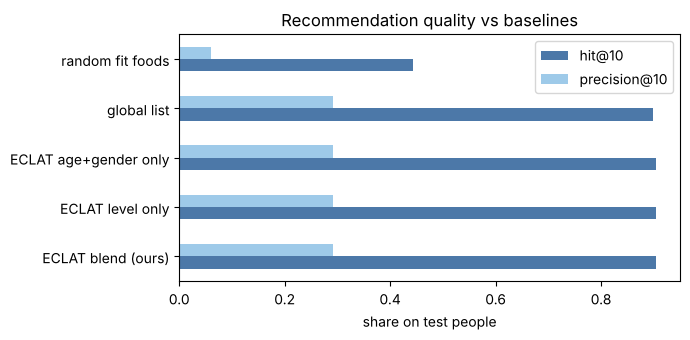

In [20]:
test_scores = evaluate(train, test)
print("Test set (used once):"); print(test_scores.round(3).to_string())
ours, rand = test_scores.loc["ECLAT blend (ours)"], test_scores.loc["random fit foods"]
print(f"\nHit Rate@10 on unseen people: {ours['hit@10']:.1%} (random fit foods: {rand['hit@10']:.1%})")
print(f"On average {ours['precision@10'] * TOP_K:.1f} of the 10 foods were eaten (random: {rand['precision@10'] * TOP_K:.1f})")
print(f"Same result straight from the Pipeline: Hit Rate@10 = {pipe_train.score(test):.1%}")
ax = test_scores[["hit@10", "precision@10"]].plot.barh(figsize=(7, 3.5), color=["#4c78a8", "#9ecae9"])
ax.set_xlabel("share on test people"); ax.set_title("Recommendation quality vs baselines")
plt.tight_layout(); plt.show()

## Part 7: Do the suggestions change from level to level?
### Step 9: Level-by-level comparison

In [21]:
t0 = time.time()
pipe_all = make_sucrose_pipeline().fit(data)
model_all = pipe_all.named_steps["eclat"].model_
print(f"Final ECLAT on all {len(data)} transactions finished in {time.time() - t0:.0f} s\n")
rows = []
for g in GROUPS:
    prev = None
    for lv in LEVELS:
        L = list(recommend_foods(model_all, lv, g).food)
        if prev is not None:
            rows.append({"group": g, "step": f"{prev[0]} -> {lv}", "new foods in top 10": len(set(L) - set(prev[1])),
                         "order changed": L != prev[1]})
        prev = (lv, L)
steps = pd.DataFrame(rows)
print(steps.groupby("step", sort=False).agg(**{"avg new foods": ("new foods in top 10", "mean"),
                                               "groups with changed list": ("order changed", "sum")}).round(1).to_string())

Final ECLAT on all 1885 transactions finished in 50 s

                    avg new foods  groups with changed list
step                                                       
<80 -> 80-99                  0.0                         0
80-99 -> 100-119              2.8                         6
100-119 -> 120-139            1.2                         6
120-139 -> 140-159            0.0                         6
140-159 -> 160-179            0.0                         4
160-179 -> 180-199            1.0                         6
180-199 -> 200+               2.0                         6


In [22]:
g = "40-59 female"
table = pd.DataFrame({lv: [pretty(f) for f in recommend_foods(model_all, lv, g, k=6).food] for lv in LEVELS}, index=range(1, 7))
print(f"Top 6 foods for a {g} at each glucose level:")
print(table.T.to_string())

Top 6 foods for a 40-59 female at each glucose level:
                        1                      2                  3                     4                     5                     6
<80           Fresh fruit  White bread and rolls   Salad vegetables                  Milk      Rice and oatmeal     Cooked vegetables
80-99         Fresh fruit  White bread and rolls   Salad vegetables                  Milk      Rice and oatmeal     Cooked vegetables
100-119       Fresh fruit                   Milk   Salad vegetables     Cooked vegetables      Rice and oatmeal  Eggs boiled or fried
120-139       Fresh fruit      Cooked vegetables   Salad vegetables                  Milk      Rice and oatmeal  Eggs boiled or fried
140-159       Fresh fruit       Salad vegetables  Cooked vegetables                  Milk      Rice and oatmeal  Eggs boiled or fried
160-179       Fresh fruit       Salad vegetables  Cooked vegetables                  Milk      Rice and oatmeal  Eggs boiled or fried
180-199 

## Part 8: Evaluate the specific foods inside each group
### Step 10: Do the specific-food supports hold on unseen people?

In [23]:
ITEMS = pd.read_csv(ITEMS_FILE)
ITEM_NUT = ITEMS.set_index("code")
BASKETS = pd.read_csv(ITEM_BASKETS_FILE)
ate = (pd.crosstab(BASKETS.SEQN, BASKETS.code).clip(upper=1)
         .reindex(data.SEQN.values, fill_value=0).set_axis(data.index))

def item_fit(c, lv):
    n, lim = ITEM_NUT.loc[c], LIMITS[lv]
    sugar_ok = n.sugar_100g <= lim["sugar"] or (n.fiber_100g >= FIBER_EXCEPTION["min_fiber"] and n.sugar_100g <= FIBER_EXCEPTION["max_sugar"])
    return bool(sugar_ok and n.net_carb_100g <= lim["net_carb"] and n.sat_fat_100g <= lim["sat_fat"])

parts = [(f"level {pool_name(p)}", train.Level.isin(p), test.Level.isin(p))
         for p in sorted(set(model_train["pool_of"].values()), key=lambda p: LEVELS.index(p[0]))]
parts += [(f"group {g}", train.Group == g, test.Group == g) for g in GROUPS]

rows = []
for name, in_train, in_test in parts:
    s_tr, s_te = ate.loc[train.index[in_train]].mean(), ate.loc[test.index[in_test]].mean()
    keep = s_tr[s_tr > 0].index
    rows.append({"transactions": name, "test people": int(in_test.sum()), "specific foods": len(keep),
                 "rank correlation": round(spearmanr(s_tr[keep], s_te[keep]).correlation, 3),
                 "mean gap (% points)": round(float((s_tr[keep] - s_te[keep]).abs().mean() * 100), 2)})
item_support_check = pd.DataFrame(rows)
print(item_support_check.to_string(index=False))

       transactions  test people  specific foods  rank correlation  mean gap (% points)
    level below 100          158             932             0.610                 0.69
      level 100-119          175             952             0.606                 0.68
level 120 and above           44             592             0.425                 1.74
 group 18-39 female           76             806             0.522                 1.04
   group 18-39 male           69             742             0.504                 1.06
 group 40-59 female           62             787             0.439                 1.34
   group 40-59 male           59             775             0.469                 1.22
   group 60+ female           58             763             0.542                 1.32
     group 60+ male           53             727             0.503                 1.42


### Step 11: Does the ranking put the food people actually eat on top?

In [24]:
K_ITEMS = 3
rng = np.random.default_rng(SEED)
overall = ate.loc[train.index].mean()
hits = {"support score (ours)": [], "most eaten overall": [], "random": []}

for (lv, g), people in test.groupby(["Level", "Group"]):
    s_lv = ate.loc[train.index[train.Level.isin(model_train["pool_of"][lv])]].mean()
    s_g = ate.loc[train.index[train.Group == g]].mean()
    w = LIMITS[lv]["carb_penalty"]
    for f in recommend_foods(model_train, lv, g).food:
        cand = [c for c in ITEMS.loc[ITEMS.group == code_of(f), "code"] if c in ate.columns and item_fit(c, lv)]
        if len(cand) <= K_ITEMS:
            continue
        score = {c: (s_lv.get(c, 0) + s_g.get(c, 0)) / 2 * (1 - w * min(ITEM_NUT.loc[c, "net_carb_100g"] / 40, 1)) for c in cand}
        ours = sorted(cand, key=lambda c: (-score[c], -overall.get(c, 0)))[:K_ITEMS]
        popular = sorted(cand, key=lambda c: -overall.get(c, 0))[:K_ITEMS]
        for idx in people.index[people[f] == 1]:
            eaten = {c for c in cand if ate.at[idx, c] == 1}
            if not eaten:
                continue
            hits["support score (ours)"].append(bool(eaten & set(ours)))
            hits["most eaten overall"].append(bool(eaten & set(popular)))
            hits["random"].append(bool(eaten & set(rng.choice(cand, K_ITEMS, replace=False))))

item_ranking_eval = pd.DataFrame({name: {"hit@3": np.mean(v), "cases": len(v)} for name, v in hits.items()}).T
print("Test set (used once):"); print(item_ranking_eval.round(3).to_string())

Test set (used once):
                      hit@3  cases
support score (ours)  0.723  842.0
most eaten overall    0.734  842.0
random                0.321  842.0


## Part 9: Demo
### Step 12: `recommend(model, glucose, age, gender)`

In [25]:
recommend(model_all, 92, 25, "female")

Fasting glucose 92 mg/dL -> level 80-99 mg/dL (Normal)
People like you: 18-39 female (380 transactions) | same glucose level: below 100 mg/dL (797 transactions)
Nutrition limits for this level (per 100 g): sugar <= 15 g, net carb <= 60 g, sat. fat <= 10 g, carb penalty 0.0

Recommended foods:
                      food  score  support % (avg)  % at your level  % your age+gender  lift (level)     q  net carb g/100g
               Fresh fruit  0.439             43.9             44.4               43.4          0.95 0.227             13.4
     White bread and rolls  0.420             42.0             41.9               42.1          0.91 0.020             47.6
          Salad vegetables  0.334             33.4             33.1               33.7          0.96 0.550              3.7
                      Milk  0.324             32.4             34.3               30.5          0.91 0.039              4.8
          Rice and oatmeal  0.323             32.3             31.5               33.2

In [26]:
recommend(model_all, 115, 50, "male")

Fasting glucose 115 mg/dL -> level 100-119 mg/dL (Prediabetes)
People like you: 40-59 male (293 transactions) | same glucose level: 100-119 mg/dL (928 transactions)
Nutrition limits for this level (per 100 g): sugar <= 12 g, net carb <= 45 g, sat. fat <= 10 g, carb penalty 0.15

Recommended foods:
                      food  score  support % (avg)  % at your level  % your age+gender  lift (level)     q  net carb g/100g
               Fresh fruit  0.439             46.3             47.8               44.7          1.02 0.581             13.4
                      Milk  0.393             40.1             40.5               39.6          1.07 0.062              4.8
          Salad vegetables  0.339             34.4             35.3               33.4          1.03 0.608              3.7
          Rice and oatmeal  0.316             34.2             34.3               34.1          1.03 0.558             20.0
         Cooked vegetables  0.307             31.4             32.8              

In [27]:
recommend(model_all, 165, 67, "female")

Fasting glucose 165 mg/dL -> level 160-179 mg/dL (Diabetes)
People like you: 60+ female (293 transactions) | same glucose level: 120 and above mg/dL (160 transactions)
Nutrition limits for this level (per 100 g): sugar <= 9 g, net carb <= 24 g, sat. fat <= 8 g, carb penalty 0.6

Recommended foods:
                      food  score  support % (avg)  % at your level  % your age+gender  lift (level)     q  net carb g/100g
               Fresh fruit  0.452             56.6             52.5               60.8          1.12 0.482             13.4
                      Milk  0.382             41.2             38.8               43.7          1.03 0.919              4.8
          Salad vegetables  0.379             40.2             35.0               45.4          1.02 0.930              3.7
         Cooked vegetables  0.370             40.8             41.2               40.3          1.35 0.065              6.2
          Rice and oatmeal  0.261             37.3             35.6              

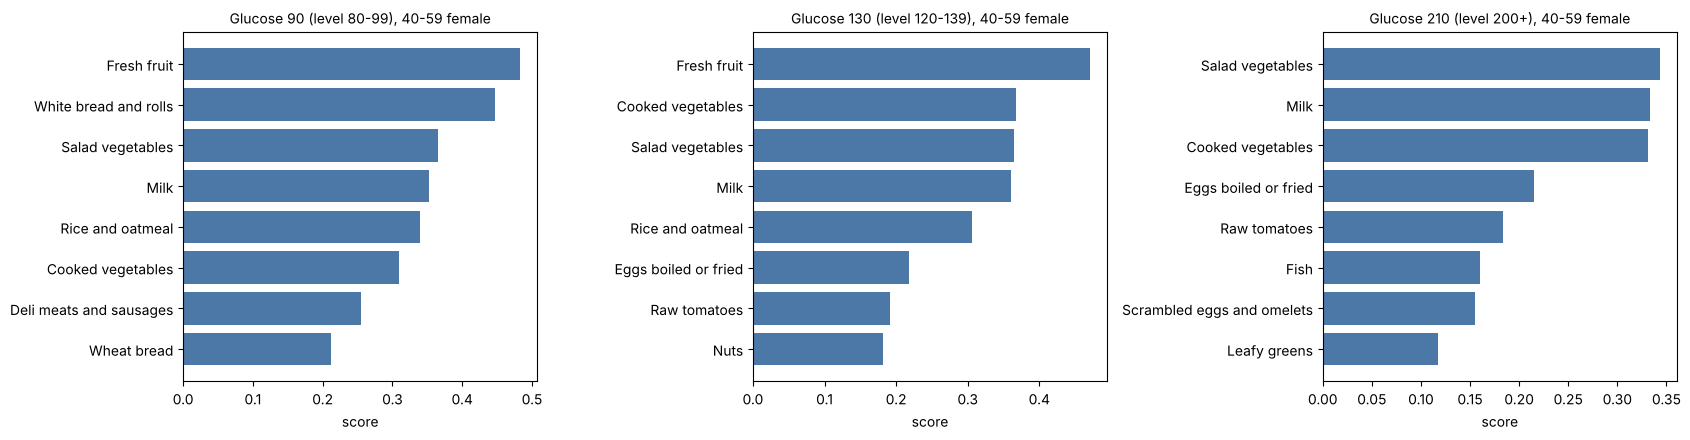

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, glu in zip(axes, [90, 130, 210]):
    lv = level_of(glu)[0]; r = recommend_foods(model_all, lv, "40-59 female", k=8).iloc[::-1]
    ax.barh(r.food.map(pretty), r.score, color="#4c78a8")
    ax.set_title(f"Glucose {glu} (level {lv}), 40-59 female", fontsize=10); ax.set_xlabel("score")
plt.tight_layout(); plt.show()